## Step 1: Environment Setup

In [2]:
from google.colab import drive
drive.mount('/content/drive')

import os
PROJECT = '/content/drive/MyDrive/ecg-project'
for sub in ['data_raw', 'data_processed', 'models', 'results']:
    os.makedirs(f'{PROJECT}/{sub}', exist_ok=True)

Mounted at /content/drive


In [3]:
!pip install -q wfdb neurokit2

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 8.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 688.9/688.9 kB 36.5 MB/s eta 0:00:00


## Step 2: Extracting the PTB-XL Dataset

In [4]:
ZIP = '/content/drive/MyDrive/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.3.zip'
print('Found zip:', os.path.exists(ZIP))

!unzip -q -o "{ZIP}" -d /content/
!mv /content/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.3 /content/ptbxl
!ls /content/ptbxl

Found zip: True
example_physionet.py	  ptbxl_v103_changelog.txt  scp_statements.csv
LICENSE.txt		  RECORDS		    SHA256SUMS.txt
ptbxl_database.csv	  records100
ptbxl_v102_changelog.txt  records500


## Step 3: Loading Metadata and Build Diagnostic Labels

In [5]:
import pandas as pd, numpy as np, ast

DATA = '/content/ptbxl'
df = pd.read_csv(f'{DATA}/ptbxl_database.csv', index_col='ecg_id')
df['scp_codes'] = df['scp_codes'].apply(ast.literal_eval)

scp = pd.read_csv(f'{DATA}/scp_statements.csv', index_col=0)
scp = scp[scp['diagnostic'] == 1]

def to_superclass(codes):
    return sorted({scp.loc[c, 'diagnostic_class'] for c in codes if c in scp.index})

df['superclass'] = df['scp_codes'].apply(to_superclass)
df = df[df['superclass'].map(len) > 0]

# Task A: abnormal (1) vs normal (0)
df['abnormal'] = (df['superclass'].apply(lambda s: s != ['NORM'])).astype(int)

print(len(df), 'records')
print(df['abnormal'].value_counts())
print(df['superclass'].explode().value_counts())

21388 records
abnormal
1    12319
0     9069
Name: count, dtype: int64
superclass
NORM    9514
MI      5469
STTC    5235
CD      4898
HYP     2649
Name: count, dtype: int64


## Step 4: Loading 12-Lead ECG Signals

In [6]:
# Loading all 100 Hz ECG waveforms into one array X of shape (records, 1000 time steps, 12 leads)
import wfdb

LEADS = wfdb.rdsamp(f"{DATA}/{df['filename_lr'].iloc[0]}")[1]['sig_name']

def load_signals(filenames):
    return np.stack([wfdb.rdsamp(f'{DATA}/{f}')[0] for f in filenames]).astype(np.float32)

X = load_signals(df['filename_lr'])
print(X.shape)
print(LEADS)

(21388, 1000, 12)
['I', 'II', 'III', 'AVR', 'AVL', 'AVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']


## Step 5: Exploratory Data Analysis


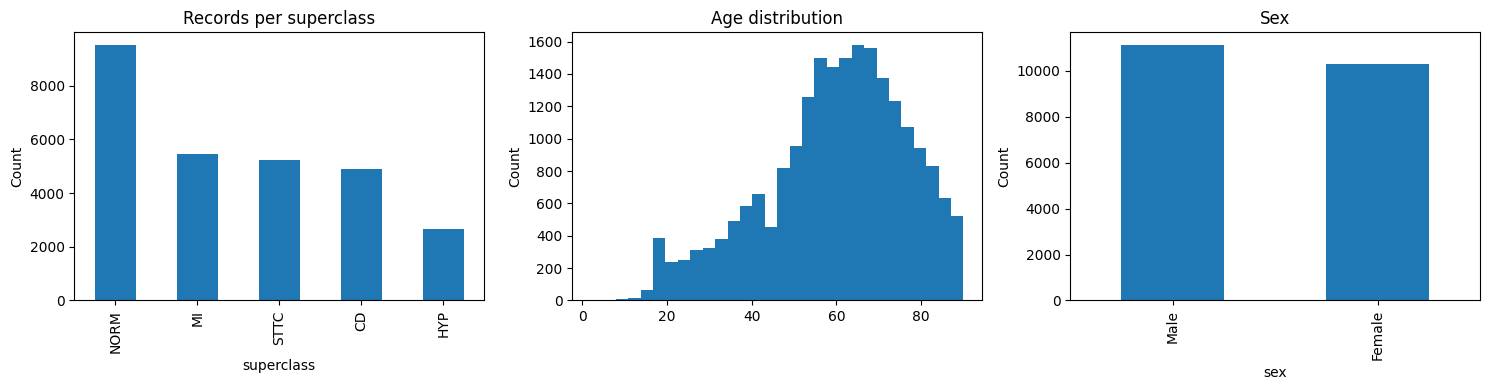

In [7]:
# (a) Exploring class balance and patient demographics
import matplotlib.pyplot as plt

FIGS = f'{PROJECT}/results/figures'
os.makedirs(FIGS, exist_ok=True)

df['age'] = df['age'].clip(upper=90)  # ages >89 are stored as 300 for anonymity

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
df['superclass'].explode().value_counts().plot(kind='bar', ax=axes[0], title='Records per superclass')
df['age'].plot(kind='hist', bins=30, ax=axes[1], title='Age distribution')
df['sex'].map({0: 'Male', 1: 'Female'}).value_counts().plot(kind='bar', ax=axes[2], title='Sex')
for ax in axes: ax.set_ylabel('Count')
plt.tight_layout()
plt.savefig(f'{FIGS}/data_overview.png', dpi=150)
plt.show()

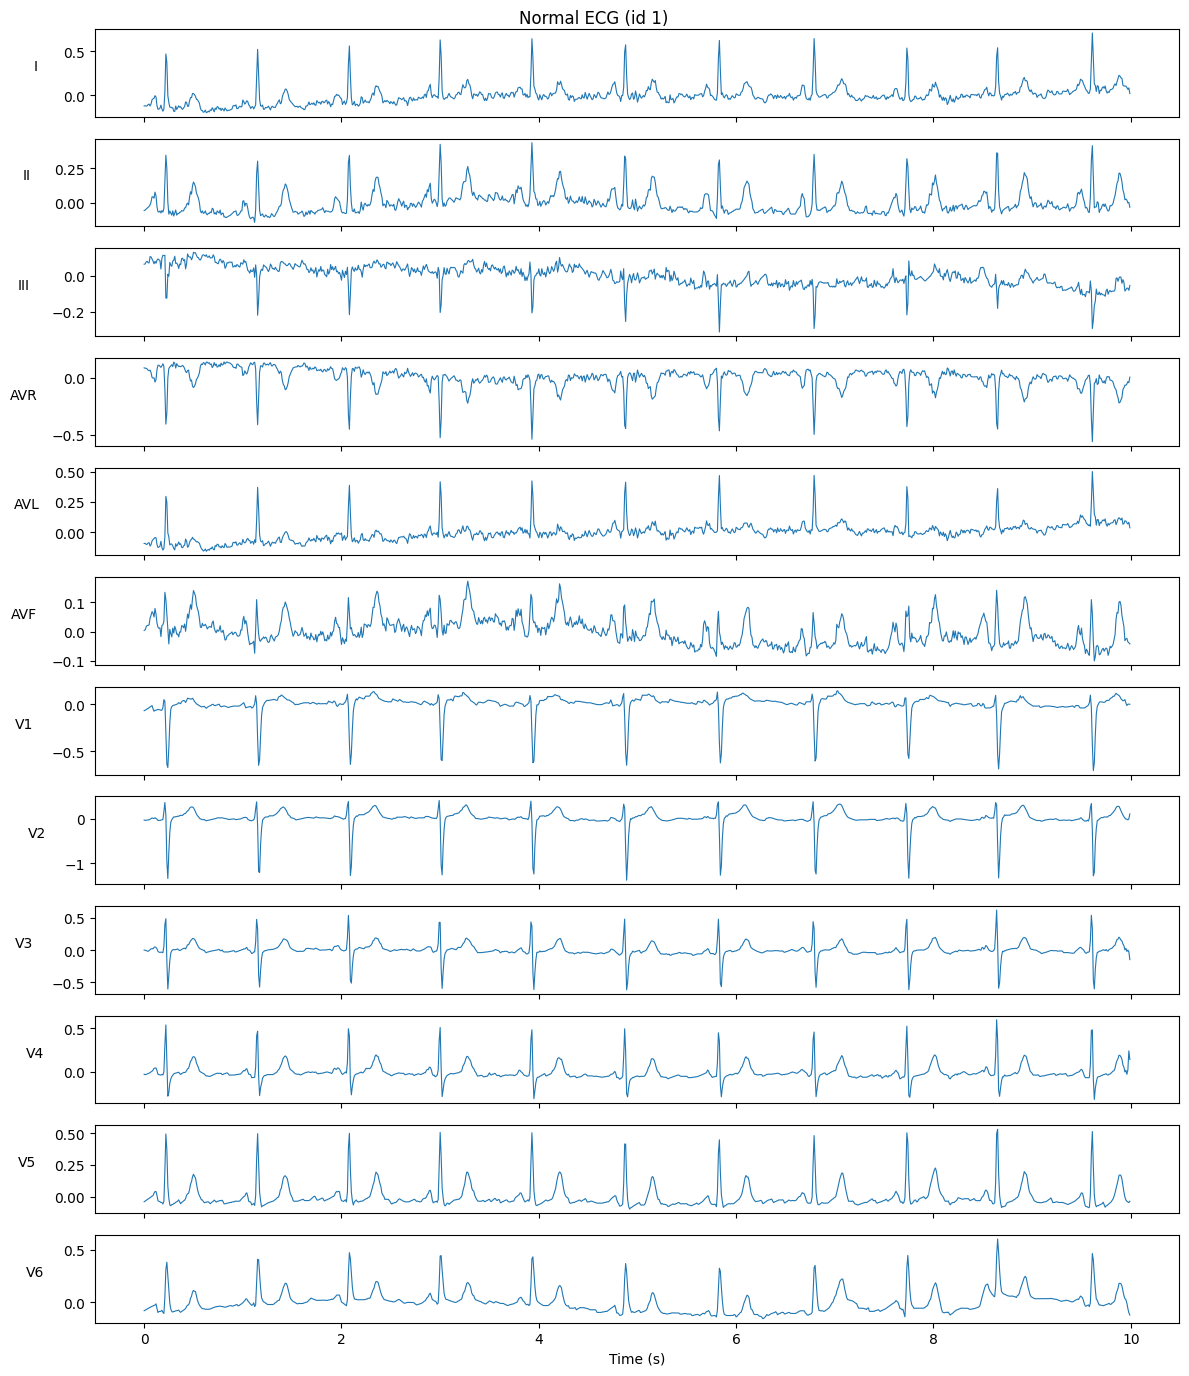

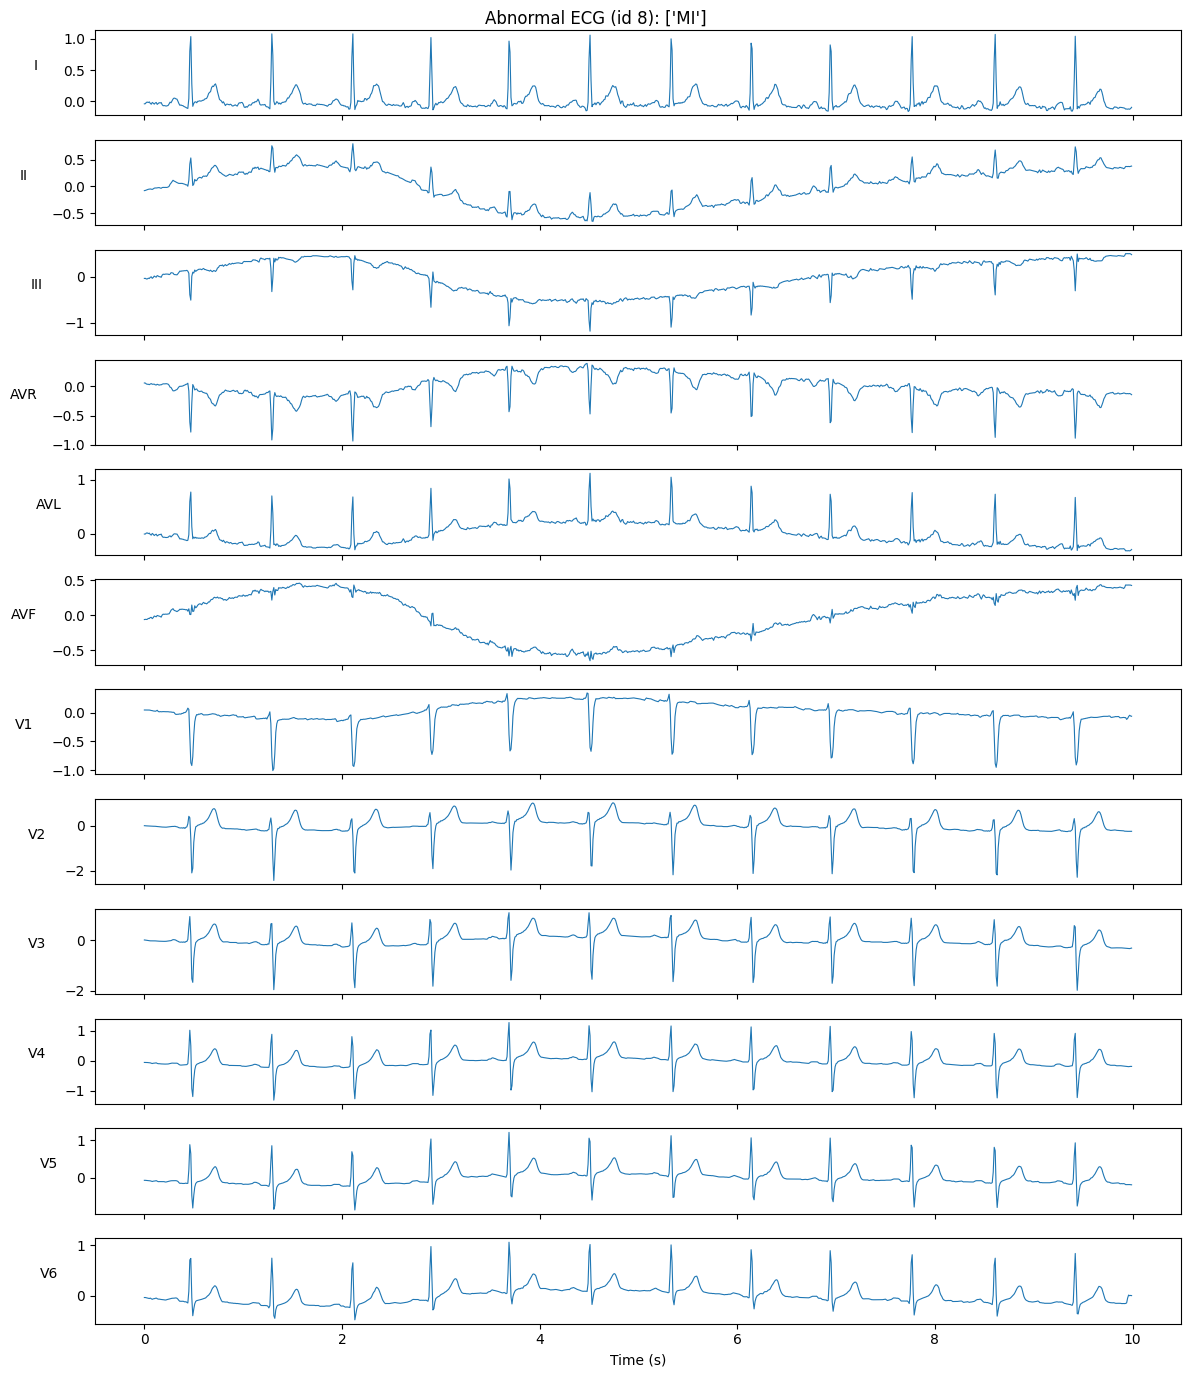

In [8]:
# (b) Defining a reusable 12-lead ECG plotting function and viewing one normal and one abnormal example
# Visualizing 12-Lead ECGs
def plot_ecg(signal, title, path=None):
    t = np.arange(signal.shape[0]) / 100
    fig, axes = plt.subplots(12, 1, figsize=(12, 14), sharex=True)
    for i, ax in enumerate(axes):
        ax.plot(t, signal[:, i], lw=0.8)
        ax.set_ylabel(LEADS[i], rotation=0, labelpad=20)
    axes[-1].set_xlabel('Time (s)')
    fig.suptitle(title)
    plt.tight_layout()
    if path: plt.savefig(path, dpi=150)
    plt.show()

i_norm = np.where(df['abnormal'] == 0)[0][0]
i_abn = np.where(df['abnormal'] == 1)[0][0]
plot_ecg(X[i_norm], f"Normal ECG (id {df.index[i_norm]})", f'{FIGS}/example_normal_raw.png')
plot_ecg(X[i_abn], f"Abnormal ECG (id {df.index[i_abn]}): {df['superclass'].iloc[i_abn]}", f'{FIGS}/example_abnormal_raw.png')

## Step 6: Preprocessing - Filtering and Normalizing

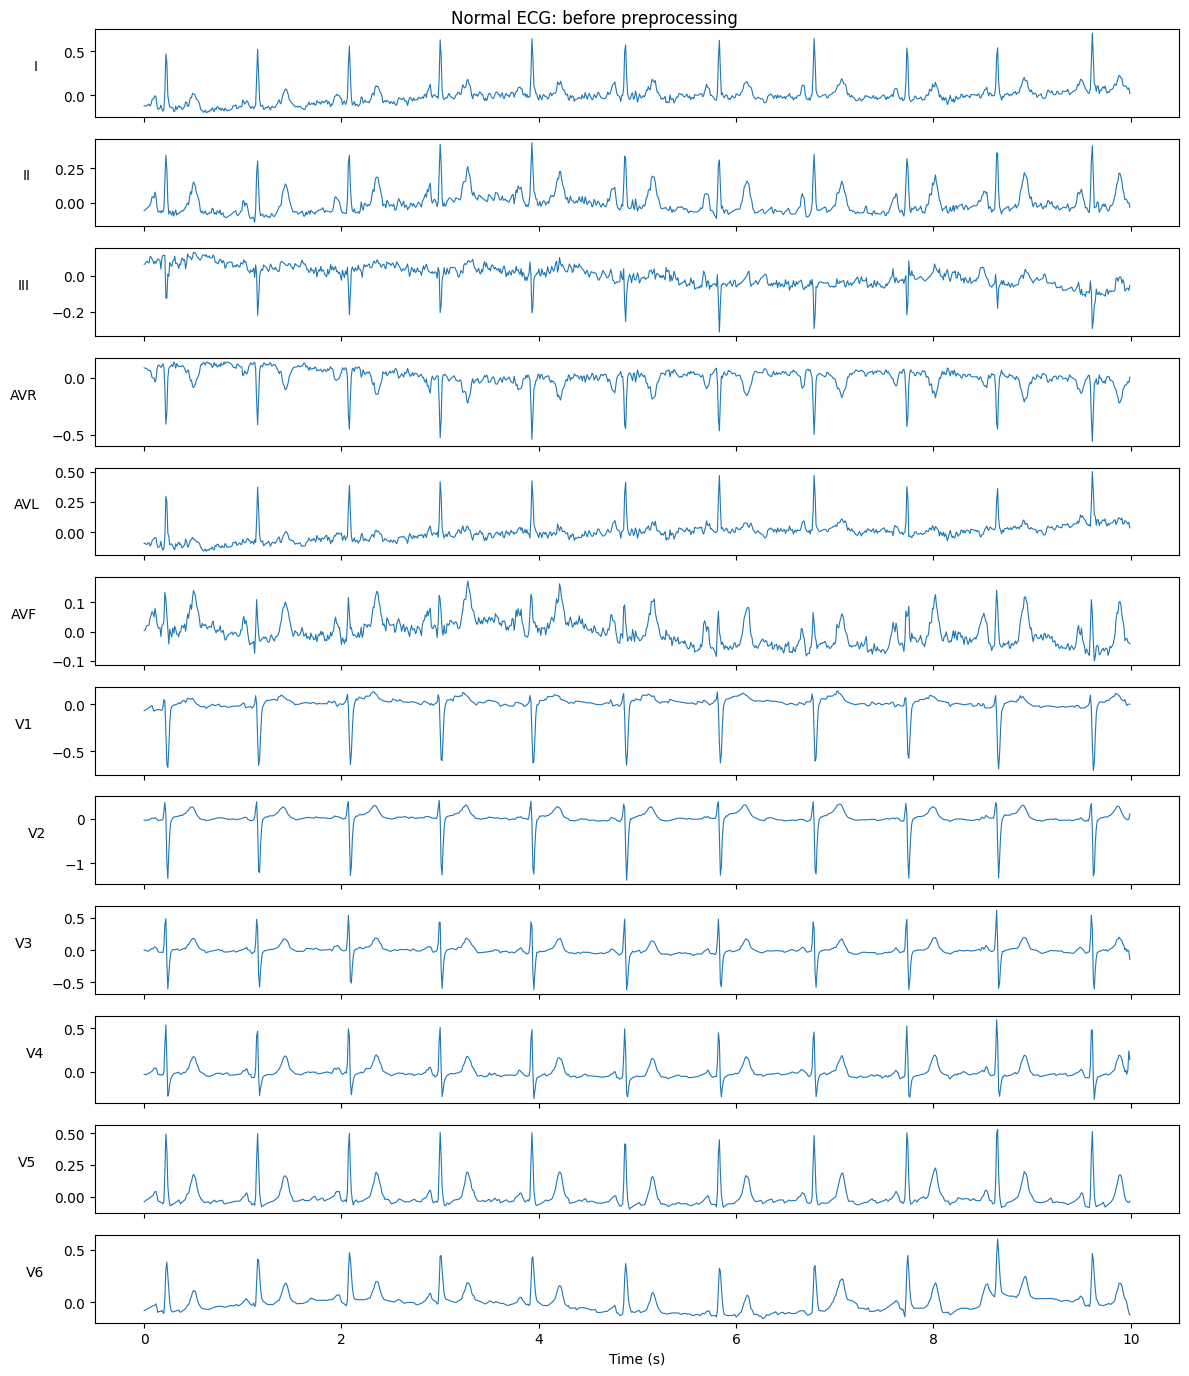

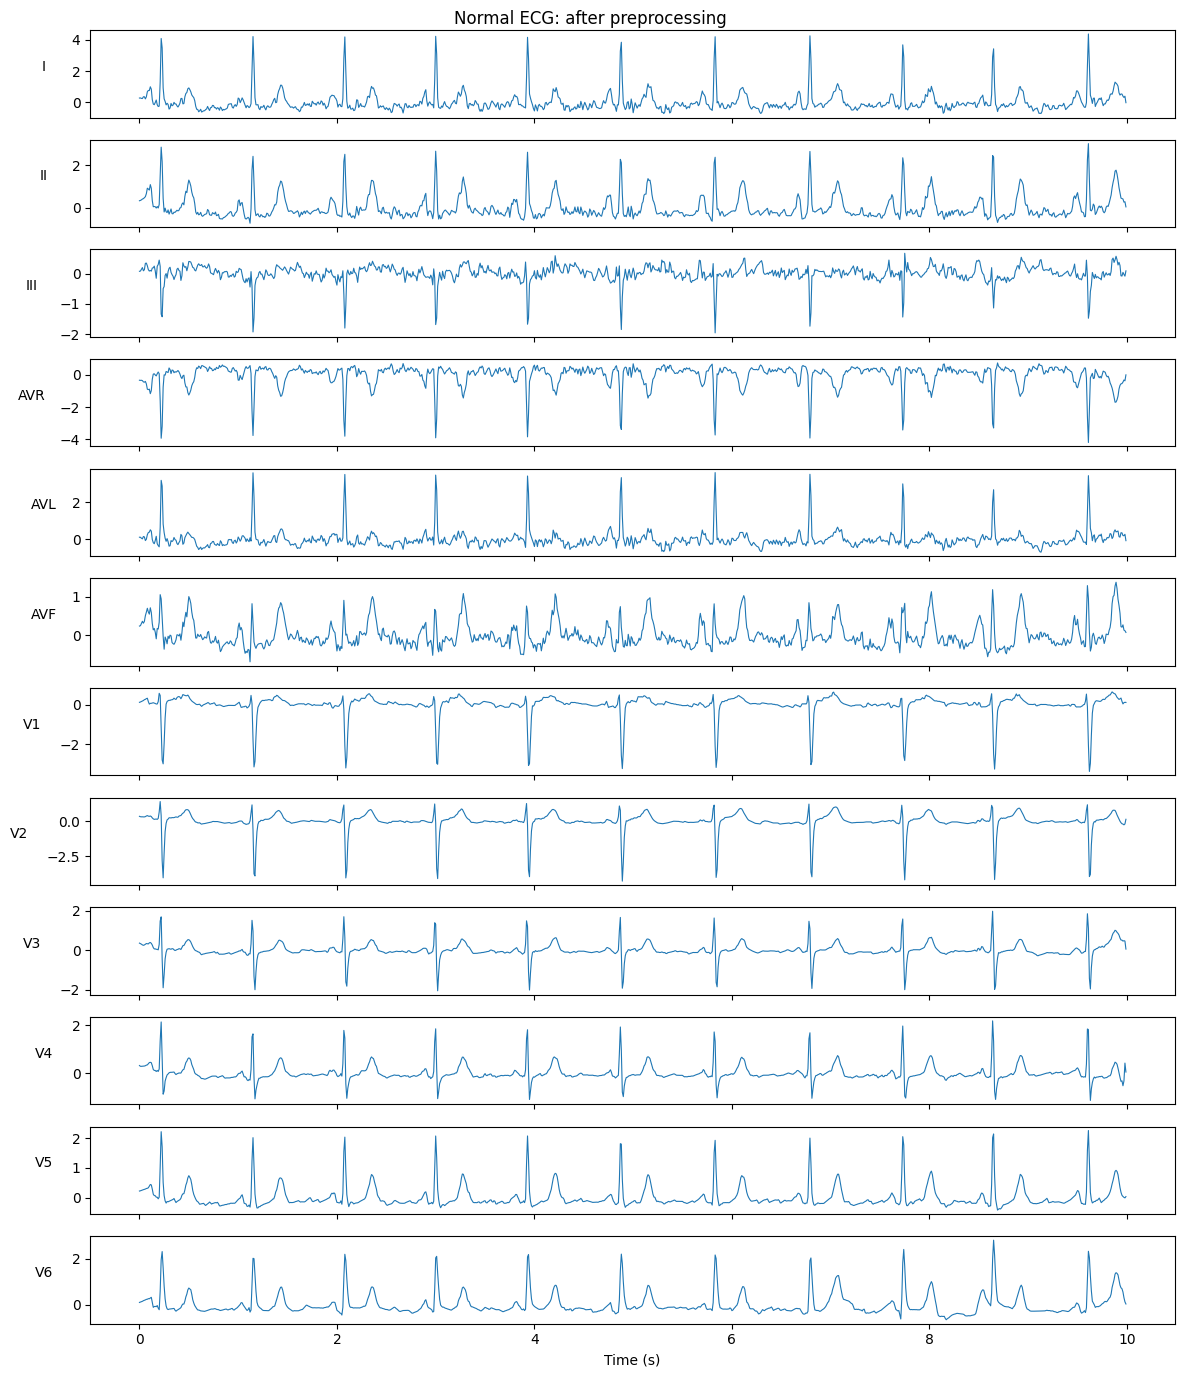

(21388, 1000, 12) float32


In [9]:
# Bandpass-filter (0.5–40 Hz) to remove baseline wander and noise, then z-normalize each lead of each ECG
from scipy.signal import butter, filtfilt

def bandpass(x, low=0.5, high=40, fs=100, order=3):
    b, a = butter(order, [low, high], btype='band', fs=fs)
    return filtfilt(b, a, x, axis=1)

raw_example = X[i_norm].copy()
X = np.concatenate([bandpass(X[i:i + 2000]).astype(np.float32) for i in range(0, len(X), 2000)])

train_mask = (df['strat_fold'] <= 8).values
mu = X[train_mask].mean(axis=(0, 1))
sd = X[train_mask].std(axis=(0, 1))
X = ((X - mu) / sd).astype(np.float32)
np.save(f'{PROJECT}/data_processed/norm_stats.npy', np.stack([mu, sd]))

plot_ecg(raw_example, 'Normal ECG: before preprocessing')
plot_ecg(X[i_norm], 'Normal ECG: after preprocessing', f'{FIGS}/example_normal_clean.png')
print(X.shape, X.dtype)

## Step 7: Building Labels, Patient-Safe Splits and Saving Processed Data

In [10]:
CLASSES = ['NORM', 'MI', 'STTC', 'CD', 'HYP']
Y_multi = np.array([[int(c in s) for c in CLASSES] for s in df['superclass']], dtype=np.float32)
y_bin = df['abnormal'].values.astype(np.float32)

splits = {
    'train': (df['strat_fold'] <= 8).values,
    'val':   (df['strat_fold'] == 9).values,
    'test':  (df['strat_fold'] == 10).values,
}

# Check that no patient appears in more than one split
pid = {k: set(df.loc[m, 'patient_id']) for k, m in splits.items()}
assert not (pid['train'] & pid['val'] or pid['train'] & pid['test'] or pid['val'] & pid['test'])

OUT = f'{PROJECT}/data_processed'
for name, mask in splits.items():
    np.save(f'{OUT}/X_{name}.npy', X[mask])
    np.save(f'{OUT}/Ymulti_{name}.npy', Y_multi[mask])
    np.save(f'{OUT}/ybin_{name}.npy', y_bin[mask])
    print(f"{name:5s}: {mask.sum():5d} records | abnormal rate {y_bin[mask].mean():.2f}")

# Metadata (one row per ECG, same order as the arrays) for the subgroup analysis in R
meta = df[['patient_id', 'age', 'sex', 'strat_fold', 'abnormal']].copy()
meta['sex'] = meta['sex'].map({0: 'M', 1: 'F'})
meta['split'] = np.select([splits['train'], splits['val']], ['train', 'val'], 'test')
meta['superclass'] = df['superclass'].str.join('|')
meta[CLASSES] = Y_multi.astype(int)
meta.to_csv(f'{OUT}/metadata.csv')
print('Saved to', OUT)

train: 17084 records | abnormal rate 0.58
val  :  2146 records | abnormal rate 0.57
test :  2158 records | abnormal rate 0.58
Saved to /content/drive/MyDrive/ecg-project/data_processed


## Step 8: Building the reusable data pipeline with Augmentation

*   List item
*   List item



In [11]:
# (a): Creating a src/ folder on Drive for reusable project code and making it importable
import sys
os.makedirs(f'{PROJECT}/src', exist_ok=True)
sys.path.append(f'{PROJECT}/src')

In [12]:
%%writefile /content/drive/MyDrive/ecg-project/src/data.py
# (b): Save reusable data-loading, augmentation and tf.data pipeline code as src/data.py
"""Loading processed PTB-XL splits and building tf.data pipelines with augmentation."""
import numpy as np
import tensorflow as tf

DATA_DIR = '/content/drive/MyDrive/ecg-project/data_processed'
CLASSES = ['NORM', 'MI', 'STTC', 'CD', 'HYP']


def load_split(name, task='binary', data_dir=DATA_DIR):
    """Load X and labels for 'train', 'val' or 'test'. task: 'binary' or 'multi'."""
    X = np.load(f'{data_dir}/X_{name}.npy')
    y = np.load(f"{data_dir}/{'ybin' if task == 'binary' else 'Ymulti'}_{name}.npy")
    return X, y


def augment(x, y):
    """Random, label-preserving changes applied to one ECG of shape (1000, 12)."""
    x = x * tf.random.uniform([1, 12], 0.9, 1.1)                         # amplitude scaling per lead
    x = x + tf.random.normal(tf.shape(x), stddev=0.03)                   # Gaussian noise
    x = tf.roll(x, tf.random.uniform([], -50, 51, tf.int32), axis=0)     # time shift up to 0.5 s
    x = x * tf.cast(tf.random.uniform([1, 12]) > 0.1, x.dtype)           # drop about 10% of leads
    return x, y


def make_dataset(X, y, training, batch_size=64, seed=42):
    """Batched tf.data pipeline; shuffling and augmentation only when training=True."""
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    if training:
        ds = ds.shuffle(len(X), seed=seed).map(augment, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)

Overwriting /content/drive/MyDrive/ecg-project/src/data.py


Train batch: (64, 1000, 12) (64,)
Val data unchanged: True


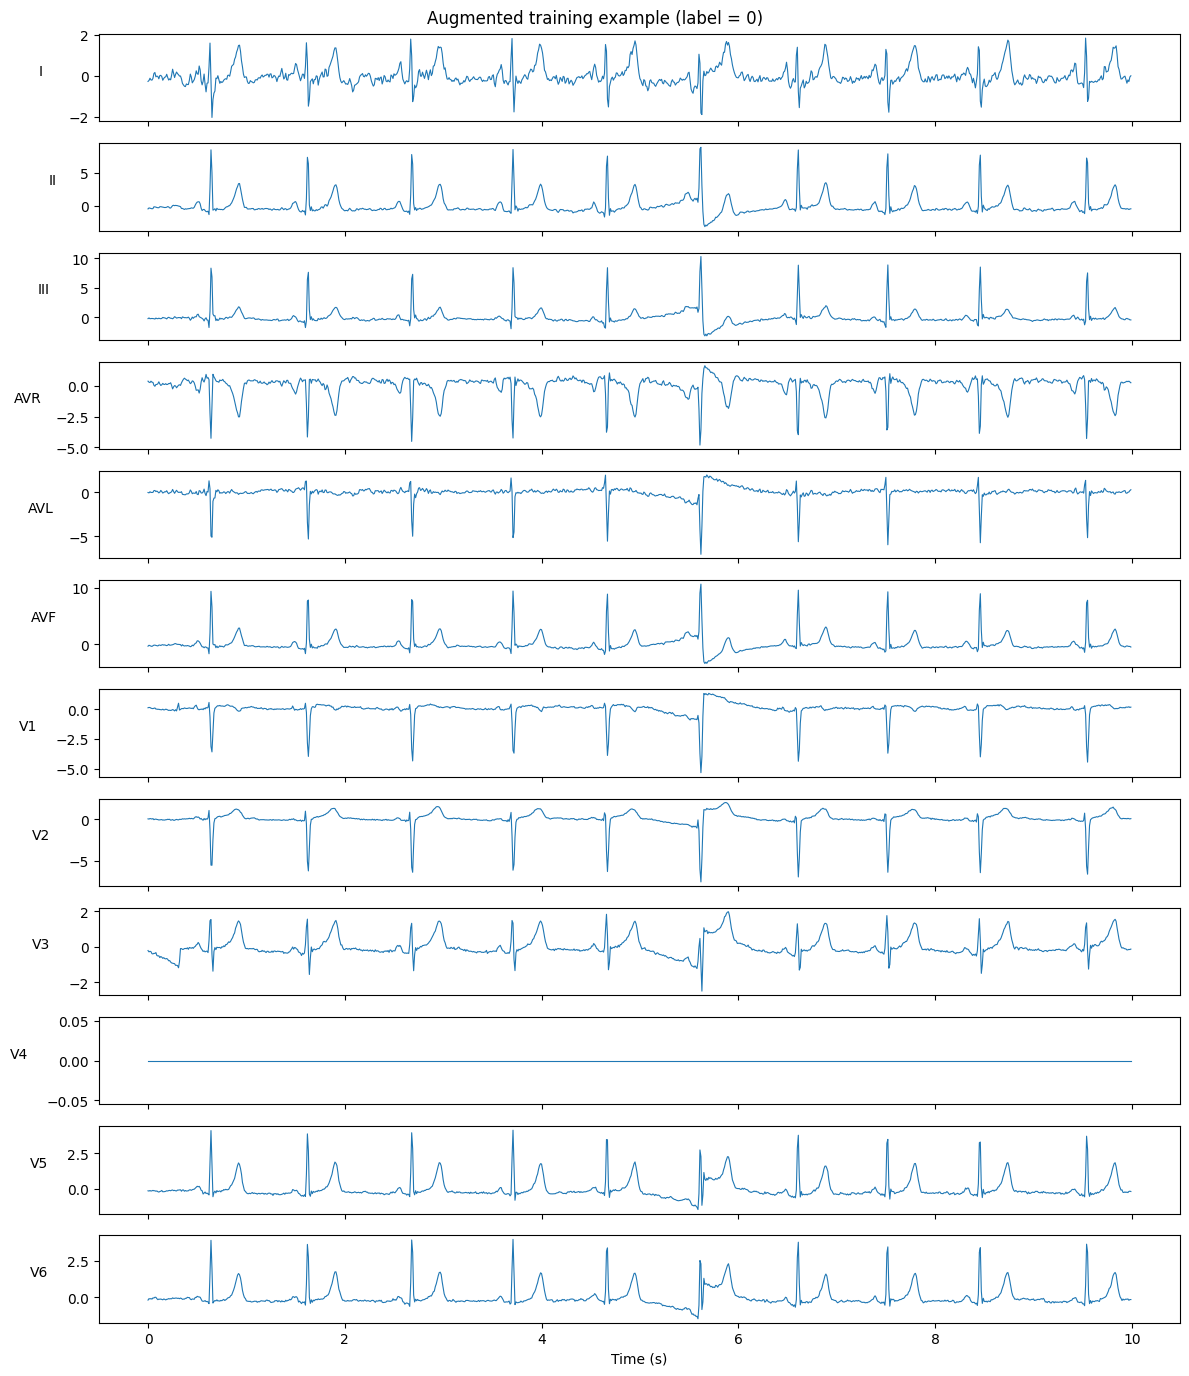

In [13]:
# (c): Testing the pipeline: check batch shapes, confirm val data is untouched, and view an augmented ECG
import importlib, data
importlib.reload(data)
import tensorflow as tf
tf.random.set_seed(42)

X_tr, y_tr = data.load_split('train')
X_va, y_va = data.load_split('val')

train_ds = data.make_dataset(X_tr, y_tr, training=True)
val_ds = data.make_dataset(X_va, y_va, training=False)

xb, yb = next(iter(train_ds))
print('Train batch:', xb.shape, yb.shape)

xv, _ = next(iter(val_ds))
print('Val data unchanged:', np.allclose(xv.numpy(), X_va[:64]))

plot_ecg(xb[0].numpy(), f'Augmented training example (label = {int(yb[0])})', f'{FIGS}/example_augmented.png')